# Breast Cancer Wisconsin: Random Forest vs SVM + Feature Importance

**Цель.** Сравнить ансамбль деревьев (bagging) и kernel-метод на одной задаче бинарной классификации и интерпретировать обе модели.

**Задача.** По 30 признакам клеточных ядер определить, злокачественная ли опухоль (1 = malignant).

**Какая метрика важна.** Пропущенная опухоль намного опаснее ложной тревоги, поэтому главные метрики это Recall (полнота, доля найденных опухолей) при Precision ≥ 0.9 и Cost (стоимость ошибок) с FP = 1, FN = 20.

**Что значит «готово».** Пройдены все шаги протокола, тест использован один раз, результаты сверены с эталоном.

Уровень проекта: ML. Постоянный код лежит в `src/`, таблицы в `results/tables/`, графики в `results/figures/`.

## 1. Настройка

*2026-11-06. Цель: импорты, seed, пути, версии библиотек.*

In [1]:
import sys                                    # для добавления корня проекта в путь импорта
import warnings                               # для проверки предупреждений sklearn
from pathlib import Path                      # работа с путями

ROOT = Path.cwd().parent                      # ноутбук лежит в notebooks/, корень на уровень выше
sys.path.insert(0, str(ROOT))                 # чтобы работал импорт из src/

import matplotlib                             # настройка графиков
import matplotlib.pyplot as plt               # построение графиков
import numpy as np                            # массивы и случайные числа
import pandas as pd                           # таблицы
import sklearn                                # проверка версии
from sklearn.base import clone                # чистая копия модели с теми же параметрами
from sklearn.datasets import make_classification  # синтетика для теста масштабируемости
from sklearn.dummy import DummyClassifier     # наивная модель для baseline
from sklearn.inspection import permutation_importance  # важность через перестановку
from sklearn.metrics import confusion_matrix  # матрица ошибок
from sklearn.model_selection import GridSearchCV, cross_val_score  # подбор и кросс-валидация
from sklearn.svm import SVC                   # проверка устаревшего параметра probability

from src.data import SEED, load_data, split_data, split_summary  # данные
from src.importance import group_columns, group_permutation_importance  # групповая важность
from src.metrics import bootstrap_cost_diff, evaluate, fit_timed, repeated_cv  # метрики
from src.models import RF_GRID, SVM_GRID, make_rf, make_svm  # модели и сетки

TABLES = ROOT / "results" / "tables"          # сюда сохраняем таблицы для отчёта
FIGURES = ROOT / "results" / "figures"        # сюда сохраняем графики
TABLES.mkdir(parents=True, exist_ok=True)     # создаём папки, если их ещё нет
FIGURES.mkdir(parents=True, exist_ok=True)

# Один цвет закреплён за одной моделью на всех графиках
COLORS = {"RF": "#2a78d6", "SVM": "#eb6834", "SVM rbf": "#1baf7a", "benign": "#2a78d6", "malignant": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,   # убираем лишние рамки
    "axes.grid": True, "grid.color": "#e7e6e2", "grid.linewidth": 0.8, "axes.axisbelow": True,  # тихая сетка
    "axes.edgecolor": "#9b9a94", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10,
})
pd.set_option("display.max_columns", 30, "display.max_colwidth", 90, "display.width", 200)
print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])

sklearn 1.9.1 | pandas 3.1.0 | numpy 2.5.4 | python 3.14.5


## 2. Данные и превью

*2026-11-06. Цель: посмотреть на данные глазами, проверить пропуски и баланс классов.*

**Источник.** Breast Cancer Wisconsin, `sklearn.datasets.load_breast_cancer`. Датасет встроен в sklearn, поэтому `data/raw/` не нужна. Копия на Kaggle: uciml/breast-cancer-wisconsin-data. Одна строка это один пациент, столбцы это свойства ядер клеток на снимке.

**Ожидания до анализа.** Пропусков нет, злокачественных около 37%. Признаки в сильно разных масштабах: площадь в сотнях, гладкость в десятых. Радиус, периметр и площадь почти дублируют друг друга, ведь это один и тот же размер ядра.

**Важно.** В sklearn метка 0 = malignant, поэтому метка инвертируется в `load_data`: иначе Recall считался бы для доброкачественных.

In [2]:
X, y = load_data()                                     # X: 30 признаков, y: 1 = злокачественная
display(pd.concat([y, X], axis=1).sample(5, random_state=SEED).round(3))  # случайные строки, а не только первые
print("Размер:", X.shape)
print("Пропусков:", int(X.isna().sum().sum()), "| полных дублей строк:", int(X.duplicated().sum()))
print(f"Злокачественных: {int(y.sum())} из {len(y)} ({y.mean():.1%})")

,malignant,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,...,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
204,0,12.47,18.60,81.09,481.9,0.100,0.106,0.080,0.038,0.192,0.064,0.396,1.044,2.497,30.29,...,0.019,0.027,0.010,0.018,0.004,14.97,24.64,96.05,677.9,0.143,0.238,0.267,0.102,0.301,0.088
70,1,18.94,21.31,123.60,1130.0,0.090,0.103,0.108,0.080,0.158,0.055,0.789,0.798,5.486,96.05,...,0.017,0.023,0.014,0.014,0.002,24.86,26.58,165.90,1866.0,0.119,0.234,0.269,0.179,0.255,0.066
131,1,15.46,19.48,101.70,748.9,0.109,0.122,0.147,0.081,0.193,0.058,0.474,0.786,3.094,48.31,...,0.015,0.028,0.011,0.014,0.002,19.26,26.00,124.90,1156.0,0.155,0.239,0.379,0.151,0.284,0.080
431,0,12.40,17.68,81.47,467.8,0.105,0.132,0.077,0.028,0.181,0.071,0.177,1.460,2.204,15.43,...,0.033,0.049,0.012,0.022,0.006,12.88,22.91,89.61,515.8,0.145,0.263,0.240,0.074,0.256,0.094
540,0,11.54,14.44,74.65,402.9,0.100,0.112,0.067,0.026,0.182,0.068,0.278,1.768,1.628,20.86,...,0.041,0.056,0.015,0.018,0.006,12.26,19.68,78.78,457.8,0.134,0.212,0.180,0.069,0.233,0.081


Размер: (569, 30)
Пропусков: 0 | полных дублей строк: 0
Злокачественных: 212 из 569 (37.3%)


In [3]:
# Диапазоны показывают, зачем нужен StandardScaler
ranges = X.describe().T[["mean", "std", "min", "max"]].sort_values("std", ascending=False).round(4)
display(pd.concat([ranges.head(4), ranges.tail(3)]))

# Выбросы по правилу 1.5 IQR считаем, но не удаляем: сначала надо понять, что они значат
q1, q3 = X.quantile(0.25), X.quantile(0.75)            # первый и третий квартили каждого признака
is_out = (X < q1 - 1.5 * (q3 - q1)) | (X > q3 + 1.5 * (q3 - q1))  # True там, где значение за границей
has_out = is_out.any(axis=1)                           # есть ли у пациента хотя бы один выброс
print(f"Пациентов хотя бы с одним выбросом: {has_out.sum()} из {len(X)}")
print(f"Доля злокачественных среди них: {y[has_out].mean():.1%}, среди остальных: {y[~has_out].mean():.1%}")

,mean,std,min,max
worst area,880.5831,569.3570,185.2000,4254.0000
mean area,654.8891,351.9141,143.5000,2501.0000
area error,40.3371,45.4910,6.8020,542.2000
worst perimeter,107.2612,33.6025,50.4100,251.2000
concave points error,0.0118,0.0062,0.0000,0.0528
smoothness error,0.0070,0.0030,0.0017,0.0311
fractal dimension error,0.0038,0.0026,0.0009,0.0298


Пациентов хотя бы с одним выбросом: 171 из 569
Доля злокачественных среди них: 66.7%, среди остальных: 24.6%


**Вывод.** Пропусков и дублей нет, злокачественных 37.3%: дисбаланс умеренный, undersampling не нужен, но accuracy брать нельзя. Масштабы отличаются на порядки: `worst area` до 4254, `fractal dimension error` до 0.03. Выбросы не удаляем: у пациентов с выбросом доля злокачественных 66.7% против 24.6% у остальных, то есть это в основном сигнал, а не ошибки ввода.

## 3. EDA

*2026-11-06. Цель: понять, какие признаки разделяют классы и насколько они связаны между собой.*

**Вопросы и ожидания.** (1) Разделяют ли классы размер и вогнутость ядра? Ожидаю, что да: опухолевые ядра обычно крупнее и неправильнее. (2) Насколько сильно коррелируют radius, perimeter и area? Ожидаю корреляцию около 1, поэтому важность будет делиться между ними.

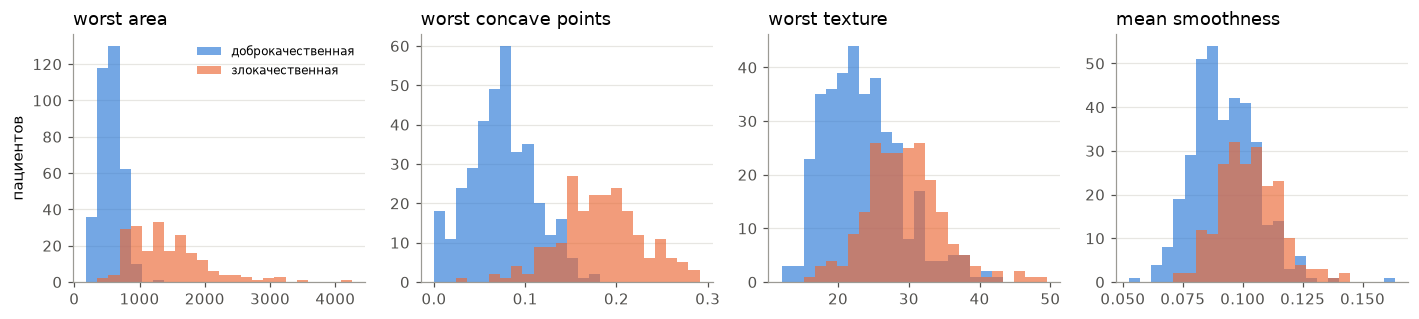

In [4]:
# Распределения четырёх признаков по классам
features = ["worst area", "worst concave points", "worst texture", "mean smoothness"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3))
for ax, feature in zip(axes, features):
    bins = np.linspace(X[feature].min(), X[feature].max(), 25)  # общие корзины для обоих классов
    ax.hist(X.loc[y == 0, feature], bins=bins, alpha=0.65, color=COLORS["benign"], label="доброкачественная")
    ax.hist(X.loc[y == 1, feature], bins=bins, alpha=0.65, color=COLORS["malignant"], label="злокачественная")
    ax.set_title(feature)
    ax.grid(axis="x", visible=False)                   # вертикальная сетка здесь не нужна
axes[0].set_ylabel("пациентов")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "eda_distributions.png")
plt.show()

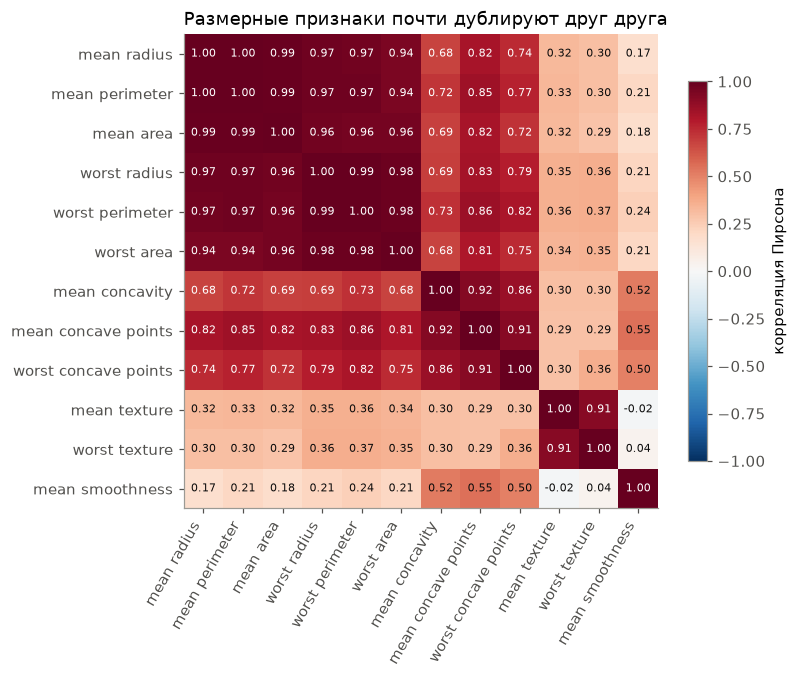

corr(mean radius, mean perimeter) = 0.998
corr(mean radius, mean area)      = 0.987


In [5]:
# Корреляции между признаками группы размера и формы
subset = ["mean radius", "mean perimeter", "mean area", "worst radius", "worst perimeter", "worst area",
          "mean concavity", "mean concave points", "worst concave points", "mean texture", "worst texture", "mean smoothness"]
corr = X[subset].corr()                                # матрица корреляций Пирсона
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)   # расходящаяся шкала с нейтральным нулём
ax.set_xticks(range(len(subset)), subset, rotation=60, ha="right")
ax.set_yticks(range(len(subset)), subset)
ax.grid(False)
for i in range(len(subset)):
    for j in range(len(subset)):
        value = corr.iloc[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(value) > 0.6 else "#0b0b0b")
fig.colorbar(im, label="корреляция Пирсона", shrink=0.8)
ax.set_title("Размерные признаки почти дублируют друг друга")
fig.savefig(FIGURES / "eda_correlation.png")
plt.show()
print("corr(mean radius, mean perimeter) =", round(X["mean radius"].corr(X["mean perimeter"]), 3))
print("corr(mean radius, mean area)      =", round(X["mean radius"].corr(X["mean area"]), 3))

**Вывод.** Ожидания подтвердились. Размер и вогнутость хорошо разделяют классы, текстура слабее, а у `mean smoothness` распределения сильно перекрываются. Корреляция `mean radius` и `mean perimeter` равна 0.998: это почти один признак, поэтому важность будет делиться между дублёрами (проверка в разделе 8).

## 4. Разбиение и масштабирование

*2026-11-06. Цель: разбить 70/15/15 со stratify и измерить эффект StandardScaler.*

**Scaler внутри Pipeline.** При `fit` он обучается только на переданных данных, а при кросс-валидации заново на каждом обучающем фолде. Поэтому утечки данных (data leakage) нет.

**Ожидания.** SVM без масштабирования резко просядет: RBF-ядро считает расстояния, а они будут определяться площадью. Для леса масштаб не важен, деревья сравнивают признак с порогом.

In [6]:
X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y)   # 70/15/15 со stratify
splits = split_summary(y_train, y_val, y_test)                      # размеры и доли класса
splits.to_csv(TABLES / "splits.csv", index=False)
display(splits)

,сплит,строк,злокачественных,доля
0,train,398,148,0.372
1,val,85,32,0.376
2,test,86,32,0.372


In [7]:
# Baseline: всегда отвечает самым частым классом
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Dummy: accuracy на val {baseline.score(X_val, y_val):.3f}, Recall {(baseline.predict(X_val)[y_val == 1] == 1).mean():.3f}")

# Один и тот же SVM отличается только наличием StandardScaler
scaling = pd.DataFrame({
    "SVM без scaler": evaluate(make_svm(scaled=False).fit(X_train, y_train), X_val, y_val),
    "SVM + StandardScaler": evaluate(make_svm(scaled=True).fit(X_train, y_train), X_val, y_val),
    "RF без scaler (для сравнения)": evaluate(make_rf().fit(X_train, y_train), X_val, y_val),
}).T
scaling.to_csv(TABLES / "scaling_effect.csv")
display(scaling.round(3))

Dummy: accuracy на val 0.624, Recall 0.000


,ROC-AUC,Recall,Precision,F1,TP,FP,FN,TN,Cost
SVM без scaler,0.972,0.688,1.0,0.815,22.0,0.0,10.0,53.0,200.0
SVM + StandardScaler,0.996,0.875,1.0,0.933,28.0,0.0,4.0,53.0,80.0
RF без scaler (для сравнения),0.994,0.906,1.0,0.951,29.0,0.0,3.0,53.0,60.0


**Вывод.** Baseline находит 0 опухолей при accuracy 0.624: это показывает, почему accuracy здесь обманывает. SVM со scaler находит 28 из 32 опухолей против 22 из 32 без него. Без масштабирования расстояния в RBF-ядре определяются признаками площади с самыми большими значениями, а мелкие признаки почти не учитываются. Модели на этом этапе не ошибаются в сторону ложных тревог (FP = 0), поэтому вся разница в пропусках.

## 5. Базовые модели

*2026-11-06. Цель: дефолтные модели, метрики ROC-AUC, Recall, Precision, F1 и время обучения.*

Для ROC-AUC у SVM используется `decision_function` (расстояние до гиперплоскости): `src/metrics.py`, функция `scores`. Время это медиана 5 запусков, лес обучается на одном ядре, как и SVC.

**Ожидания.** Обе модели сильно обойдут baseline. Разница между ними будет небольшой.

In [8]:
# Проверяем, объявлен ли probability=True устаревшим в нашей версии sklearn
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")                    # ловим все предупреждения
    SVC(probability=True).fit(X_train, y_train)        # обучаем с устаревшим параметром
print("Предупреждения:", [f"{w.category.__name__}: {str(w.message)[:110]}" for w in caught] or "нет")

Предупреждения: ['FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifi']


In [9]:
base_models = {"RF": make_rf(), "SVM (rbf) + scaler": make_svm()}   # дефолтные параметры
rows = {}
for name, model in base_models.items():
    model, seconds = fit_timed(model, X_train, y_train, repeats=5)  # обучение с замером времени
    rows[name] = {**evaluate(model, X_val, y_val), "Время, с": seconds}  # метрики на val
base_table = pd.DataFrame(rows).T
base_table.to_csv(TABLES / "base_models.csv")
display(base_table.round(4))

,ROC-AUC,Recall,Precision,F1,TP,FP,FN,TN,Cost,"Время, с"
RF,0.9941,0.9062,1.0,0.9508,29.0,0.0,3.0,53.0,60.0,0.1001
SVM (rbf) + scaler,0.9959,0.8750,1.0,0.9333,28.0,0.0,4.0,53.0,80.0,0.0029


**Вывод.** Обе модели сильно лучше baseline и не дают ложных тревог на val. Лучший Recall у RF: 0.906 против 0.875, это одна опухоль из 32. ROC-AUC чуть выше у SVM: 0.996 против 0.994. На сотнях строк SVM обучается в десятки раз быстрее леса из 100 деревьев. Предупреждение это подтверждает: `probability` объявлен устаревшим в sklearn 1.9, поэтому `decision_function` здесь правильный выбор.

## 6. Настройка гиперпараметров

*2026-11-06. Цель: GridSearchCV (cv=5, scoring="recall"), таблица экспериментов, выбор по Recall при Precision ≥ 0.9.*

**Правило выбора зафиксировано до запуска теста.** Сначала Precision на val ≥ 0.9, затем максимальный Val Recall. Само правило не говорит, что делать при равенстве, поэтому при равном Val Recall берём больший CV Recall: он посчитан на 398 строках, а val содержит только 85.

Сетка SVM включает `gamma` и для линейного ядра, где он ни на что не влияет. Это задублированные комбинации, поэтому они дают одинаковый результат.

In [10]:
# Поиск по сетке: 5 фолдов, оптимизируем Recall. refit обучает лучшую модель на всём train
rf_search, rf_seconds = fit_timed(GridSearchCV(make_rf(), RF_GRID, cv=5, scoring="recall", n_jobs=-1), X_train, y_train)
svm_search, svm_seconds = fit_timed(GridSearchCV(make_svm(), SVM_GRID, cv=5, scoring="recall", n_jobs=-1), X_train, y_train)

for name, search, seconds in [("RF", rf_search, rf_seconds), ("SVM", svm_search, svm_seconds)]:
    ranks = search.cv_results_["rank_test_score"]      # место каждой комбинации
    print(f"{name}: лучшие {search.best_params_}")
    print(f"  CV Recall {search.best_score_:.4f}, комбинаций {len(ranks)}, с первым местом {(ranks == 1).sum()}, поиск {seconds:.1f} с")

# Какие комбинации SVM делят первое место
svm_cv = pd.DataFrame(svm_search.cv_results_)
display(svm_cv[svm_cv["rank_test_score"] == 1][["params", "mean_test_score", "std_test_score"]])

RF: лучшие {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}
  CV Recall 0.9253, комбинаций 24, с первым местом 16, поиск 10.3 с
SVM: лучшие {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
  CV Recall 0.9453, комбинаций 24, с первым местом 2, поиск 0.2 с


,params,mean_test_score,std_test_score
11,"{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}",0.945287,0.077538
13,"{'svc__C': 10, 'svc__gamma': 'scale', 'svc__kernel': 'rbf'}",0.945287,0.077538


In [11]:
# Фиксированные строки таблицы экспериментов
experiments = [
    ("RF", "по умолчанию", make_rf()),
    ("RF", f"лучшие из GridSearchCV: {rf_search.best_params_}", clone(rf_search.best_estimator_)),
    ("SVM", "kernel=linear, C=1", make_svm(kernel="linear", C=1)),
    ("SVM", "kernel=rbf, C=1, gamma=scale", make_svm(kernel="rbf", C=1, gamma="scale")),
    ("SVM", f"лучшие из GridSearchCV: {svm_search.best_params_}", clone(svm_search.best_estimator_)),
]
# Дополнительная строка: class_weight, которого нет в эталонной сетке
extra = ("SVM", "доп.: kernel=rbf, C=1, gamma=scale, class_weight=balanced", make_svm(class_weight="balanced"))

def experiment_row(number, family, params, model):
    cv_recall = cross_val_score(clone(model), X_train, y_train, cv=5, scoring="recall").mean()  # те же фолды, что в поиске
    model, seconds = fit_timed(model, X_train, y_train, repeats=5)  # обучение на всём train
    metrics = evaluate(model, X_val, y_val)                # только val, тест не трогаем
    return {"№": number, "Модель": family, "Параметры": params, "CV Recall": cv_recall, "Val Recall": metrics["Recall"],
            "Val Precision": metrics["Precision"], "Время, с": seconds, "Val Cost": metrics["Cost"]}, model

fitted, rows = {}, []
for number, (family, params, model) in enumerate(experiments + [extra], start=1):
    row, fitted[number] = experiment_row(number, family, params, model)  # сохраняем и строку, и модель
    rows.append(row)
table = pd.DataFrame(rows)
table.to_csv(TABLES / "experiments.csv", index=False)
display(table.round({"CV Recall": 3, "Val Recall": 3, "Val Precision": 3, "Время, с": 4}))

,№,Модель,Параметры,CV Recall,Val Recall,Val Precision,"Время, с",Val Cost
0,1,RF,по умолчанию,0.925,0.906,1.000,0.1000,60
1,2,RF,"лучшие из GridSearchCV: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf'...",0.925,0.906,1.000,0.0999,60
2,3,SVM,"kernel=linear, C=1",0.918,0.906,1.000,0.0029,60
3,4,SVM,"kernel=rbf, C=1, gamma=scale",0.945,0.875,1.000,0.0029,80
4,5,SVM,"лучшие из GridSearchCV: {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}",0.945,0.906,0.935,0.0034,62
5,6,SVM,"доп.: kernel=rbf, C=1, gamma=scale, class_weight=balanced",0.952,0.969,0.969,0.0031,21


In [12]:
def select(candidates):
    # Precision >= 0.9, затем лучший Val Recall, при равенстве лучший CV Recall
    allowed = candidates[candidates["Val Precision"] >= 0.9]
    return allowed.sort_values(["Val Recall", "CV Recall"], ascending=False).iloc[0]

main = table[table["№"] <= 5]                          # пять основных строк
best_overall = select(main)
best_rf = select(main[main["Модель"] == "RF"])         # финалист от леса
best_svm = select(main[main["Модель"] == "SVM"])       # финалист от SVM
print("Лучшая по правилу отбора: №", best_overall["№"], "|", best_overall["Параметры"])
print("Финалист RF: №", best_rf["№"], "| финалист SVM: №", best_svm["№"])
print("Если добавить строку 6, победитель: №", select(table)["№"])

Лучшая по правилу отбора: № 5 | лучшие из GridSearchCV: {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}
Финалист RF: № 1 | финалист SVM: № 5
Если добавить строку 6, победитель: № 6


**Вывод.** По правилу отбора побеждает строка 5, но только с дополнительным критерием: строки 1, 2, 3 и 5 делят Val Recall 0.906, а CV Recall выше у строки 5 (0.945). Сетка мало что даёт. У леса 16 из 24 комбинаций делят первое место, поэтому «лучшие совпадают с дефолтом» означает ничью, а не доказанный оптимум. У SVM первое место делят две комбинации, и выбор gamma=0.1 поднял Val Recall ценой двух ложных тревог. Дополнительная строка 6 показала намного больше: `class_weight=balanced` повысил штраф за ошибку на редком классе и дал Val Recall 0.969 при Precision 0.969.

## 7. Устойчивость: повторная кросс-валидация

*2026-11-06. Цель: понять, не случайна ли разница. На val всего 32 злокачественных случая, поэтому одна ошибка меняет Recall на 0.031.*

Считаем на train + val (483 строки), тест не участвует. Гиперпараметры выбраны на части этих данных, поэтому оценка немного оптимистична, но для сравнения моделей между собой это приемлемо.

In [13]:
X_dev, y_dev = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])   # всё, кроме теста
finalists = {"RF": fitted[int(best_rf["№"])], "SVM (строка 5)": fitted[int(best_svm["№"])], "SVM balanced (строка 6)": fitted[6]}
stability = repeated_cv(finalists, X_dev, y_dev, n_repeats=10)      # 10 повторов по 5 фолдов
summary = stability.groupby("Модель", sort=False).agg(["mean", "std"]).round(3)
summary.to_csv(TABLES / "repeated_cv.csv")
display(summary)

Recall        Precision          Cost        
                          mean    std      mean    std   mean     std
Модель                                                               
RF                       0.926  0.011     0.959  0.006  275.1  37.531
SVM (строка 5)           0.948  0.007     0.937  0.008  199.5  23.806
SVM balanced (строка 6)  0.955  0.005     0.953  0.009  170.5  17.018

**Вывод.** На 10 повторах порядок моделей сохраняется: SVM находит больше опухолей, чем RF (Recall 0.948 против 0.926), а Precision у него ниже (0.937 против 0.959). По Cost выигрывает SVM (около 200 против 275), лучший результат у `class_weight=balanced` (около 170). Здесь std показывает только зависимость от перемешивания фолдов на одних и тех же данных, а не полную неопределённость.

## 8. Интерпретация: Feature Importance

*2026-11-06. Цель: три способа оценить важность, сравнение топ-5, влияние корреляций и предметный смысл.*

**Gini importance (RF).** Для каждого признака суммируется, насколько его разбиения уменьшили нечистоту Джини, с весом по числу объектов в узле, затем значения усредняются по деревьям. Считается по train и может быть завышена для признаков с большим числом порогов.

**coef_ (linear SVM).** Коэффициенты гиперплоскости. Сравнимы между собой только после масштабирования. Знак показывает сторону: плюс двигает к классу 1 (злокачественная), но только при прочих равных.

**Permutation importance (RBF SVM).** У RBF-ядра нет коэффициентов в исходных признаках, поэтому измеряем поведение модели: перемешиваем один столбец на отложенной выборке и смотрим, насколько упала метрика. Модель при этом не переобучается. Большое падение значит, что модель опиралась на признак. Метрика здесь ROC-AUC: Recall на 32 случаях слишком грубый и меняется скачками.

**Ожидания.** Лес выберет размер и вогнутость. Перестановка одного признака у RBF SVM даст малые значения, так как его дублёр останется нетронутым.

In [14]:
rf_model = fitted[int(best_rf["№"])]                   # финалист RF
linear_svm = fitted[3]                                 # kernel=linear, C=1
rbf_svm = fitted[int(best_svm["№"])]                   # финалист SVM

gini = pd.Series(rf_model.feature_importances_, X.columns).sort_values(ascending=False)   # встроенная важность леса
coef = pd.Series(linear_svm.named_steps["svc"].coef_[0], X.columns)                       # коэффициенты со знаком
coef_abs = coef.abs().sort_values(ascending=False)     # важность это модуль коэффициента
# 30 перестановок на каждый признак на val: модель эти данные не видела
perm = permutation_importance(rbf_svm, X_val, y_val, scoring="roc_auc", n_repeats=30, random_state=SEED, n_jobs=-1)
perm_mean = pd.Series(perm.importances_mean, X.columns).sort_values(ascending=False)

top5 = {"Gini (RF)": gini, "|coef_| (linear SVM)": coef_abs, "Permutation (RBF SVM)": perm_mean}
top5_table = pd.DataFrame({name: [f"{f} ({v:.3f})" for f, v in s.head(5).items()] for name, s in top5.items()}, index=range(1, 6))
top5_table.to_csv(TABLES / "top5_features.csv")
display(top5_table)

# Пересечения топ-5
sets = {name: set(s.head(5).index) for name, s in top5.items()}
names = list(sets)
for i in range(3):
    for j in range(i + 1, 3):
        print(f"{names[i]} ∩ {names[j]}:", sorted(sets[names[i]] & sets[names[j]]) or "нет")
print("Общие для всех трёх:", sorted(sets[names[0]] & sets[names[1]] & sets[names[2]]) or "нет")

,Gini (RF),|coef_| (linear SVM),Permutation (RBF SVM)
1,worst area (0.168),mean concavity (1.028),worst texture (0.009)
2,mean concave points (0.111),worst texture (0.960),worst fractal dimension (0.006)
3,worst concave points (0.102),mean concave points (0.925),worst radius (0.006)
4,worst radius (0.081),radius error (0.752),worst perimeter (0.006)
5,worst perimeter (0.079),area error (0.733),worst concavity (0.006)


Gini (RF) ∩ |coef_| (linear SVM): ['mean concave points']
Gini (RF) ∩ Permutation (RBF SVM): ['worst perimeter', 'worst radius']
|coef_| (linear SVM) ∩ Permutation (RBF SVM): ['worst texture']
Общие для всех трёх: нет


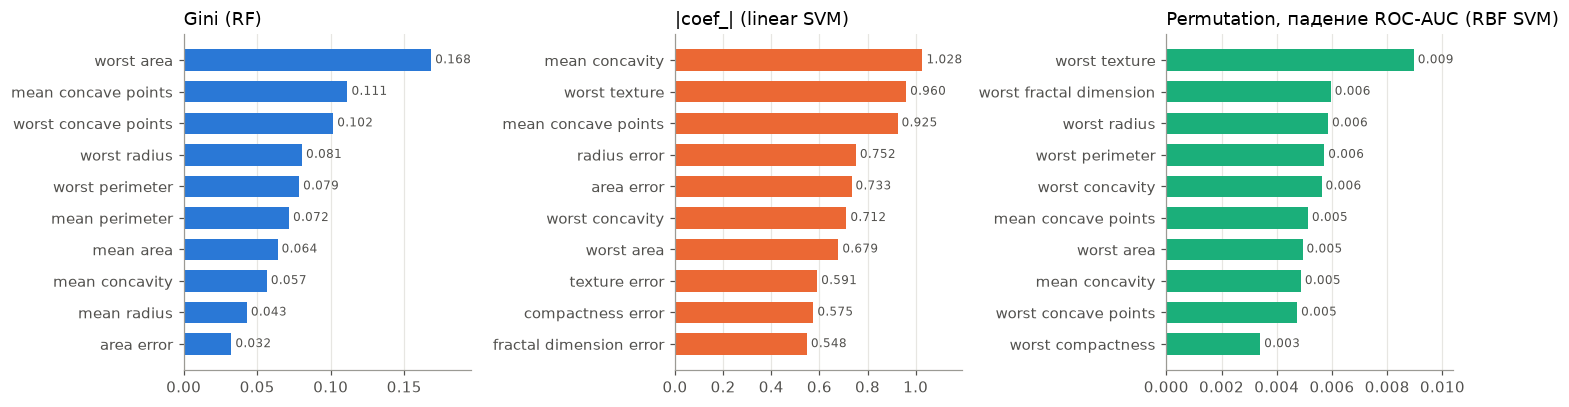

In [15]:
# Топ-10 каждого метода. Шкалы разные, поэтому у каждого метода своя ось
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
panels = [("Gini (RF)", gini, COLORS["RF"]), ("|coef_| (linear SVM)", coef_abs, COLORS["SVM"]), ("Permutation, падение ROC-AUC (RBF SVM)", perm_mean, COLORS["SVM rbf"])]
for ax, (title, series, color) in zip(axes, panels):
    top = series.head(10).iloc[::-1]                   # самый важный наверху
    ax.barh(top.index, top.values, color=color, height=0.68)
    for position, value in enumerate(top.values):
        ax.text(value, position, f" {value:.3f}", va="center", fontsize=8, color="#52514e")  # подпись значения
    ax.set_title(title)
    ax.margins(x=0.16)
    ax.grid(axis="y", visible=False)                   # горизонтальная сетка мешает полосам
fig.tight_layout()
fig.savefig(FIGURES / "feature_importance.png")
plt.show()

In [16]:
# Влияние корреляций: перемешиваем сразу всю группу, а не один столбец
groups = group_columns(X.columns)
group_svm = group_permutation_importance(rbf_svm, X_val, y_val, groups).assign(модель="RBF SVM")
group_rf = group_permutation_importance(rf_model, X_val, y_val, groups).assign(модель="RF")
group_table = pd.concat([group_svm, group_rf], ignore_index=True)
group_table.to_csv(TABLES / "group_permutation.csv", index=False)
display(group_table.round(4))
print("Сумма одиночных перестановок группы размера у RBF SVM:", round(perm_mean[groups["размер (radius, perimeter, area)"]].sum(), 4))
print("Максимум одиночной перестановки у RBF SVM:", round(perm_mean.max(), 4))

,группа,признаков,падение ROC-AUC,std,модель
0,"размер (radius, perimeter, area)",9,0.1390,0.0280,RBF SVM
1,"форма контура (concavity, concave points, compactness)",9,0.0549,0.0214,RBF SVM
2,текстура (texture),3,0.0162,0.0095,RBF SVM
3,"прочее (smoothness, symmetry, fractal dimension)",9,0.0142,0.0090,RBF SVM
4,"размер (radius, perimeter, area)",9,0.1436,0.0328,RF
5,"форма контура (concavity, concave points, compactness)",9,0.0601,0.0202,RF
6,текстура (texture),3,0.0068,0.0027,RF
7,"прочее (smoothness, symmetry, fractal dimension)",9,0.0007,0.0017,RF


Сумма одиночных перестановок группы размера у RBF SVM: 0.0316
Максимум одиночной перестановки у RBF SVM: 0.009


In [17]:
# Предметный смысл: как признаки ведут себя в каждом классе (только train)
top_union = list(dict.fromkeys(list(gini.head(5).index) + list(coef_abs.head(5).index) + list(perm_mean.head(5).index)))
means = X_train.groupby(y_train).mean().T              # среднее по классам
direction = pd.DataFrame({
    "среднее, доброкач.": means[0],
    "среднее, злокач.": means[1],
    "разница в std": (means[1] - means[0]) / X_train.std(),  # >0: у злокачественных значение выше
    "coef_ linear SVM": coef,                          # знак с учётом остальных признаков
}).loc[top_union]
# Признак расхождения: сам по себе признак растёт со злокачественностью, а коэффициент отрицательный
direction["знаки расходятся"] = np.sign(direction["разница в std"]) != np.sign(direction["coef_ linear SVM"])
direction.to_csv(TABLES / "feature_direction.csv")
display(direction.round(3))
all_flips = pd.DataFrame({"разница в std": (means[1] - means[0]) / X_train.std(), "coef_": coef})
flips = all_flips[np.sign(all_flips["разница в std"]) != np.sign(all_flips["coef_"])]
print("Признаков из 30, где знак coef_ противоречит простому сравнению классов:", len(flips))
display(flips.sort_values("разница в std", ascending=False).head(6).round(3))

,"среднее, доброкач.","среднее, злокач.",разница в std,coef_ linear SVM,знаки расходятся
worst area,562.065,1425.436,1.523,0.679,False
mean concave points,0.025,0.088,1.587,0.925,False
worst concave points,0.075,0.182,1.611,-0.000,True
worst radius,13.407,21.177,1.601,0.542,False
worst perimeter,87.166,141.582,1.614,0.260,False
mean concavity,0.047,0.159,1.374,1.028,False
worst texture,23.809,29.488,0.929,0.960,False
radius error,0.285,0.613,1.176,0.752,False
area error,21.303,72.379,1.172,0.733,False
worst fractal dimension,0.080,0.091,0.611,-0.265,True


Признаков из 30, где знак coef_ противоречит простому сравнению классов: 10


,разница в std,coef_
worst concave points,1.611,-0.000
mean compactness,1.220,-0.398
worst compactness,1.177,-0.280
worst fractal dimension,0.611,-0.265
compactness error,0.522,-0.575
concavity error,0.406,-0.133


**Вывод.**

1. **Совпадения топ-5.** Общих признаков у всех трёх методов нет. Попарно: Gini и coef_ делят `mean concave points`, Gini и permutation делят `worst radius` и `worst perimeter`, coef_ и permutation делят `worst texture`. Но смысловые группы совпадают: размер, вогнутость контура и текстура.
2. **Влияние корреляций.** Лес выбирает из дублёров случайно и размазывает между ними важность. Линейный SVM распределяет вес между ними произвольно: у 10 признаков из 30 знак coef_ противоречит простому сравнению классов. Например, `worst concave points` очень сильно различает классы, но его коэффициент около нуля. Перестановка одного признака даёт максимум 0.009, потому что дублёр остаётся целым. Перемешивание всей группы размера роняет ROC-AUC у RBF SVM на 0.139, у RF на 0.144. Это более чем в 4 раза больше суммы одиночных перестановок этой группы (0.032). Поэтому надёжнее сравнивать группы, а не отдельные признаки.
3. **Предметный смысл.** Вероятность злокачественной опухоли растёт у крупных ядер (radius, perimeter, area), с вогнутым неровным контуром (concavity, concave points) и с неоднородной текстурой (texture). Это связь в данных, а не доказанная причина. Permutation на 85 строках дополнительно шумит, поэтому порядок внутри его топ-5 ненадёжен.

## 9. Финальная оценка на тесте

*2026-11-06. Цель: ROC-AUC, Recall, Precision, Cost (FP = 1, FN = 20), время.*

Финалисты определены кодом раздела 6 до этой ячейки, тест используется один раз. Модели обучены только на train, как в разделе 6. Строка 6 заявлена заранее как дополнительная и не заменяет основное сравнение.

In [18]:
test_models = {"RF": rf_model, "SVM": rbf_svm, "SVM balanced (доп.)": fitted[6]}
seconds_of = {"RF": table.loc[table["№"] == best_rf["№"], "Время, с"].iloc[0],
              "SVM": table.loc[table["№"] == best_svm["№"], "Время, с"].iloc[0],
              "SVM balanced (доп.)": table.loc[table["№"] == 6, "Время, с"].iloc[0]}
test_rows = {name: {**evaluate(model, X_test, y_test), "Время, с": seconds_of[name]} for name, model in test_models.items()}
test_table = pd.DataFrame(test_rows).T
test_table.to_csv(TABLES / "test_results.csv")
display(test_table.round(4))

,ROC-AUC,Recall,Precision,F1,TP,FP,FN,TN,Cost,"Время, с"
RF,0.9991,0.9062,1.0000,0.9508,29.0,0.0,3.0,54.0,60.0,0.1000
SVM,0.9959,0.9375,0.9091,0.9231,30.0,3.0,2.0,51.0,43.0,0.0034
SVM balanced (доп.),1.0000,0.9688,1.0000,0.9841,31.0,0.0,1.0,54.0,20.0,0.0031


In [19]:
# Значимо ли различие Cost на 86 пациентах? Бутстрап по одним и тем же пациентам
pred = {name: model.predict(X_test) for name, model in test_models.items()}
print("Cost(RF) - Cost(SVM):", bootstrap_cost_diff(y_test, pred["RF"], pred["SVM"]))
print("Cost(RF) - Cost(SVM balanced):", bootstrap_cost_diff(y_test, pred["RF"], pred["SVM balanced (доп.)"]))

# Разбор ошибок: на каких пациентах ошиблась хотя бы одна модель
errors = pd.DataFrame({"истина": y_test, **pred}, index=y_test.index)
wrong = errors[(errors[list(pred)].ne(errors["истина"], axis=0)).any(axis=1)]
display(wrong.join(X_test[["worst area", "worst concave points", "worst texture"]].round(3)))

Cost(RF) - Cost(SVM): {'разность': 17, 'ДИ 2.5%': -44.0, 'ДИ 97.5%': 80.274999999996}
Cost(RF) - Cost(SVM balanced): {'разность': 40, 'ДИ 2.5%': 0.0, 'ДИ 97.5%': 100.0}


,истина,RF,SVM,SVM balanced (доп.),worst area,worst concave points,worst texture
116,0,0,1,0,270.0,0.038,17.07
86,1,0,1,1,808.9,0.122,29.25
205,1,1,0,1,989.5,0.125,20.24
99,1,0,0,0,826.4,0.156,30.86
39,1,0,1,1,740.4,0.226,26.02
71,0,0,1,0,284.4,0.048,15.67
505,0,0,1,0,328.1,0.108,18.04


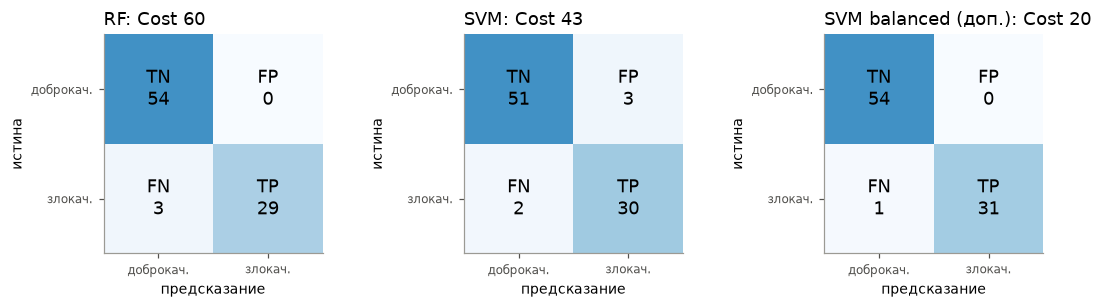

In [20]:
# Матрицы ошибок трёх моделей
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
for ax, (name, predicted) in zip(axes, pred.items()):
    matrix = confusion_matrix(y_test, predicted, labels=[0, 1])
    ax.imshow(matrix, cmap="Blues", vmin=0, vmax=matrix.max() * 1.6)  # светлая шкала, чтобы читались подписи
    labels = [["TN", "FP"], ["FN", "TP"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{labels[i][j]}\n{matrix[i, j]}", ha="center", va="center", fontsize=12)
    ax.set_xticks([0, 1], ["доброкач.", "злокач."], fontsize=8)
    ax.set_yticks([0, 1], ["доброкач.", "злокач."], fontsize=8)
    ax.set_xlabel("предсказание", fontsize=9)
    ax.set_ylabel("истина", fontsize=9)
    ax.grid(False)
    ax.set_title(f"{name}: Cost {int(test_table.loc[name, 'Cost'])}")
fig.tight_layout()
fig.savefig(FIGURES / "confusion_matrices.png")
plt.show()

**Вывод.** RF лидирует по ROC-AUC (0.999 против 0.996) и Precision (1.00 против 0.909), SVM лидирует по Recall (0.938 против 0.906) и Cost (43 против 60), потому что пропуск в 20 раз дороже ложной тревоги. Но на 86 пациентах разница не доказана: интервал бутстрапа для Cost(RF) − Cost(SVM) от −44 до +80 включает ноль. Вывод в пользу SVM опирается также на повторную кросс-валидацию из раздела 7. Дополнительная модель `class_weight=balanced` пропустила одну опухоль без ложных тревог (Cost 20), но одного теста мало для окончательного вывода, а её параметр не входил в эталонную сетку. Пациента 99 пропустили все три модели: это кандидат на разбор с врачом.

## 10. Масштабируемость: что будет на больших данных

*2026-11-06. Цель: проверить замером, а не только по теории, вопрос о миллионах записей.*

**Ожидание.** Время обучения kernel-SVM растёт примерно как n² и быстрее, у леса примерно как n·log n. Данные синтетические, поэтому важен наклон роста, а не абсолютные секунды.

модель,RF,SVM
строк,,
1000,0.24,0.02
4000,1.08,0.20
16000,6.01,2.29
32000,14.90,10.52


RF: показатель степени 1.19
SVM: показатель степени 1.84


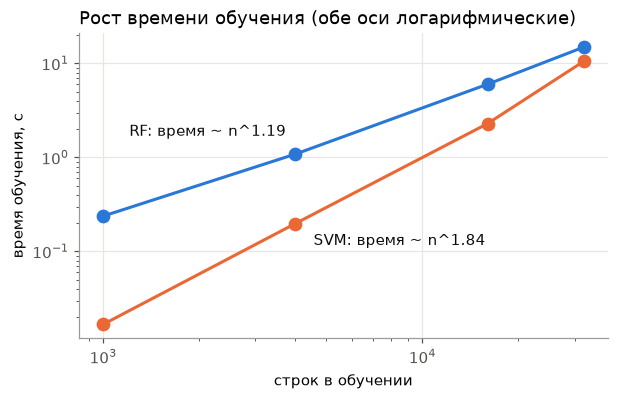

In [21]:
sizes = [1_000, 4_000, 16_000, 32_000]                 # размеры обучающей выборки
X_big, y_big = make_classification(n_samples=max(sizes) + 1_000, n_features=30, n_informative=15, flip_y=0.05, random_state=SEED)
rows = []
for n in sizes:
    for name, factory in [("RF", make_rf), ("SVM", make_svm)]:
        _, seconds = fit_timed(factory(), X_big[:n], y_big[:n])    # время обучения
        rows.append({"строк": n, "модель": name, "обучение, с": seconds})
scale = pd.DataFrame(rows)
scale.to_csv(TABLES / "scalability.csv", index=False)
display(scale.pivot(index="строк", columns="модель", values="обучение, с").round(2))

fig, ax = plt.subplots(figsize=(6.2, 3.6))
for name in ["RF", "SVM"]:
    part = scale[scale["модель"] == name]
    ax.plot(part["строк"], part["обучение, с"], marker="o", markersize=8, linewidth=2, color=COLORS[name])
    slope = np.polyfit(np.log(part["строк"]), np.log(part["обучение, с"]), 1)[0]  # наклон в логарифмах это степень роста
    # Подпись у второй точки: RF выше линии, SVM ниже, чтобы подписи не задевали линии и заголовок
    ax.annotate(f"{name}: время ~ n^{slope:.2f}", (part["строк"].iloc[1], part["обучение, с"].iloc[1]),
                xytext=(-6, 12) if name == "RF" else (12, -14), textcoords="offset points",
                ha="right" if name == "RF" else "left", color="#0b0b0b")
    print(f"{name}: показатель степени {slope:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("строк в обучении"); ax.set_ylabel("время обучения, с")
ax.set_title("Рост времени обучения (обе оси логарифмические)")
fig.savefig(FIGURES / "scalability.png")
plt.show()

**Вывод.** Замер подтверждает теорию: время SVM растёт примерно как n^1.8, леса примерно как n^1.2. На 32 000 строк SVM всё ещё быстрее по абсолютному времени, но разрыв быстро сокращается. Грубая экстраполяция на миллион строк: у SVM часы, у леса минуты на одном ядре, и лес ещё можно распараллелить. Это оценка на синтетике, а не точный прогноз. Для миллионов строк также подойдёт линейный SVM (`LinearSVC`), если хватает линейной границы.

## 11. Сверка с эталоном

*2026-11-06. Цель: сверить результаты с эталонными значениями. Время не сверяем, оно зависит от компьютера.*

In [22]:
svm_row, rf_test, svm_test = best_svm, test_table.loc["RF"], test_table.loc["SVM"]
checks = [
    ("Строк / злокачественных", "569 / 212", f"{len(y)} / {int(y.sum())}"),
    ("Сплиты train / val / test", "398 / 85 / 86", f"{len(y_train)} / {len(y_val)} / {len(y_test)}"),
    ("Доли класса в сплитах", "0.372 / 0.376 / 0.372", f"{y_train.mean():.3f} / {y_val.mean():.3f} / {y_test.mean():.3f}"),
    ("SVM Recall на val без / со scaler", "0.69 / 0.875", f"{scaling.iloc[0]['Recall']:.2f} / {scaling.iloc[1]['Recall']:.3f}"),
    ("RF на val: ROC-AUC / Recall / Precision / F1", "0.994 / 0.906 / 1.00 / 0.951", " / ".join(f"{base_table.loc['RF', m]:.3f}" for m in ["ROC-AUC", "Recall", "Precision", "F1"])),
    ("SVM на val: ROC-AUC / Recall / Precision / F1", "0.996 / 0.875 / 1.00 / 0.933", " / ".join(f"{base_table.loc['SVM (rbf) + scaler', m]:.3f}" for m in ["ROC-AUC", "Recall", "Precision", "F1"])),
    ("Лучшие параметры SVM", "rbf, C=1, gamma=0.1", str(svm_search.best_params_)),
    ("Лучшие параметры RF", "совпадают с дефолтом", str(rf_search.best_params_)),
    ("Топ-5 Gini", "worst area, mean concave points, worst concave points, worst radius, worst perimeter", ", ".join(gini.head(5).index)),
    ("Топ-5 |coef_|", "mean concavity, worst texture, mean concave points, radius error, area error", ", ".join(coef_abs.head(5).index)),
    ("Диапазон топ-5 permutation", "0.005–0.009", f"{perm_mean.head(5).min():.3f}–{perm_mean.head(5).max():.3f}"),
    ("RF на test: ROC-AUC / Recall / Precision / Cost", "0.999 / 0.906 / 1.00 / 60", f"{rf_test['ROC-AUC']:.3f} / {rf_test['Recall']:.3f} / {rf_test['Precision']:.3f} / {int(rf_test['Cost'])}"),
    ("SVM на test: ROC-AUC / Recall / Precision / Cost", "0.996 / 0.938 / 0.909 / 43", f"{svm_test['ROC-AUC']:.3f} / {svm_test['Recall']:.3f} / {svm_test['Precision']:.3f} / {int(svm_test['Cost'])}"),
]
reference = pd.DataFrame(checks, columns=["Показатель", "Эталон", "Получено"])
reference.to_csv(TABLES / "reference_check.csv", index=False)
display(reference)

,Показатель,Эталон,Получено
0,Строк / злокачественных,569 / 212,569 / 212
1,Сплиты train / val / test,398 / 85 / 86,398 / 85 / 86
2,Доли класса в сплитах,0.372 / 0.376 / 0.372,0.372 / 0.376 / 0.372
3,SVM Recall на val без / со scaler,0.69 / 0.875,0.69 / 0.875
4,RF на val: ROC-AUC / Recall / Precision / F1,0.994 / 0.906 / 1.00 / 0.951,0.994 / 0.906 / 1.000 / 0.951
5,SVM на val: ROC-AUC / Recall / Precision / F1,0.996 / 0.875 / 1.00 / 0.933,0.996 / 0.875 / 1.000 / 0.933
6,Лучшие параметры SVM,"rbf, C=1, gamma=0.1","{'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'rbf'}"
7,Лучшие параметры RF,совпадают с дефолтом,"{'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'n_estimators': 100}"
8,Топ-5 Gini,"worst area, mean concave points, worst concave points, worst radius, worst perimeter","worst area, mean concave points, worst concave points, worst radius, worst perimeter"
9,Топ-5 |coef_|,"mean concavity, worst texture, mean concave points, radius error, area error","mean concavity, worst texture, mean concave points, radius error, area error"


**Вывод.** Все сверяемые показатели совпали с эталоном. Единственная разница в округлении: нижняя граница топ-5 permutation равна 0.0056, в эталоне указано 0.005. Эталонное «совпадают с дефолтом» для лучших параметров леса верно формально, но за ней стоит ничья 16 комбинаций. Метрика для permutation в эталоне не указана, эталонный диапазон воспроизводится при `scoring="roc_auc"` на val.

## 12. Вывод

*2026-11-06.*

**Какая модель лучше при заданной цене ошибок.** SVM (RBF, C=1, gamma=0.1): Cost 43 против 60 у RF, Recall 0.938 против 0.906. На этих данных разница статистически не доказана, но направление подтверждает повторная кросс-валидация.

**Малые медицинские данные.** Лучше SVM: обучается за миллисекунды, находит больше опухолей, а его порог и веса классов удобно настраивать под цену ошибки. RF сравним по качеству и не требует масштабирования, но обучается дольше.

**Миллионы записей.** Kernel-SVM непрактичен: время обучения растёт почти как n², а предсказание зависит от числа опорных векторов. Лучше RF: он растёт почти линейно и распараллеливается.

**Что проще объяснить врачу.** RF: важность признаков даёт понятный рейтинг, а для конкретного пациента можно добавить SHAP. Ограничение: Gini не показывает направление влияния и делит важность между дублёрами, поэтому объяснять лучше группами признаков: размер, форма контура, текстура.

**Ограничения.** Один датасет из одной клиники, 32 опухоли в тесте, одна ошибка меняет Recall на 0.031. Модель не заменяет врача и не прошла внешнюю проверку.

**Что дальше.** Проверить `class_weight=balanced` или сдвиг порога на независимых данных, потому что они дали самое большое улучшение.